# Model Training 3 - Multilayer Perceptron (MLP)
### 1. Train MLP

In [ ]:
import pandas as pd
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

### (delete later) MLP using scikit learn

In [23]:
# imports
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import joblib

In [14]:
# read data
train_df = pd.read_csv("../Data/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/TestPreprocessed.csv")

In [15]:
# separate features and label
X_train = train_df.drop(columns=["LIFETIME"])
y_train = train_df["LIFETIME"]

X_test = test_df.drop(columns=["LIFETIME"])
y_test = test_df["LIFETIME"]

In [10]:
mlp = MLPRegressor(
    hidden_layer_sizes=(100, 50),    # 2 layers with 100 and 50 neurons
    activation='relu',               # ReLU is default and widely used
    solver='adam',                   # Good general-purpose optimizer
    alpha=0.0001,                    # L2 penalty (regularization term)
    learning_rate='adaptive',        # adjusts learning rate over time
    max_iter=500,                    # you can increase if convergence warnings
    early_stopping=True,             # use validation set to stop early
    random_state=42
)


In [16]:
# train model
mlp.fit(X_train, y_train)


MLPRegressor(early_stopping=True, hidden_layer_sizes=(100, 50),
             learning_rate='adaptive', max_iter=500, random_state=42)

In [24]:
# evaluate performance
y_pred = mlp.predict(X_test)

MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
R2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {MAE: .2f}")
print(f"Mean Squared Error: {MSE:.2f}, Root MSE: {RMSE: .2f}")
print(f"R² Score: {R2:.2f}")

Mean Absolute Error:  966.15
Mean Squared Error: 4724719.95, Root MSE:  2173.64
R² Score: 0.61


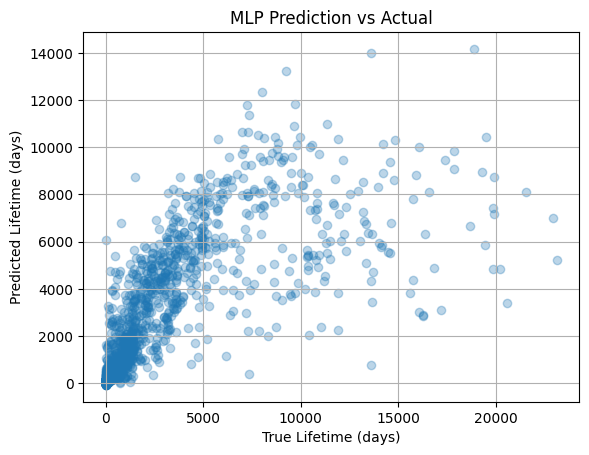

In [18]:
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("True Lifetime (days)")
plt.ylabel("Predicted Lifetime (days)")
plt.title("MLP Prediction vs Actual")
plt.grid(True)
plt.show()